## Import

In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pandas import DataFrame



## Constants

In [9]:
FILE1 = "../data/finscope_ml_training_data1.csv"
FILE2 = "../data/finscope_ml_training_data2.csv"
FILE3 = "../data/finscope_ml_training_data3.csv"
FILE4 = "../data/finscope_ml_training_data4.csv"
FILE5 = "../data/finscope_ml_training_data5.csv"
NEW_FILE = "../data/all_raw_data.csv"

### Load data

In [10]:
data1 = pd.read_csv(FILE1)
data2 = pd.read_csv(FILE2)
data3 = pd.read_csv(FILE3)
data4 = pd.read_csv(FILE4)
data5 = pd.read_csv(FILE5)
data1.head()

,date,symbol,sector,entry,sl,t1,t2,exit_price,outcome,return_pct,...,OBV,Dist_from_200MA,pat_direction,pat_confidence,rev_direction,rev_confidence,cont_direction,cont_confidence,candle_direction,candle_confidence
0,2022-07-08,TIMETECHNO,Consumer Cyclical,53.80,49.498393,66.72,79.63,49.50,SL_HIT,-8.00,...,271050976,34.66,NONE,0,NONE,0,BULLISH,85,BEARISH,80
1,2022-07-15,TIMETECHNO,Consumer Cyclical,53.07,48.826772,65.81,78.55,48.83,SL_HIT,-8.00,...,267916690,31.24,NONE,0,NONE,0,BEARISH,100,NEUTRAL,55
2,2022-07-22,TIMETECHNO,Consumer Cyclical,49.74,48.992729,51.98,54.22,48.99,SL_HIT,-1.50,...,259515858,21.63,NONE,0,BEARISH,65,BEARISH,100,BEARISH,80
3,2022-07-29,TIMETECHNO,Consumer Cyclical,52.10,47.931283,64.60,77.11,57.14,PARTIAL_RALLY,9.67,...,273362360,26.20,NONE,0,BEARISH,65,BEARISH,100,NEUTRAL,55
4,2022-08-05,TIMETECHNO,Consumer Cyclical,51.69,47.698402,63.65,75.61,53.77,PARTIAL_RALLY,4.03,...,272392810,24.06,NONE,0,BEARISH,65,BULLISH,100,NEUTRAL,55


In [11]:
data1.columns

Index(['date', 'symbol', 'sector', 'entry', 'sl', 't1', 't2', 'exit_price',
       'outcome', 'return_pct', 'rel_return_pct', 'held_days', 'score',
       'grade', 'mfe_pct', 'mae_pct', 'model_win', 'trade_win', 'dow_signal',
       'strength', 'SMA_20', 'SMA_50', 'SMA_200', 'EMA_9', 'EMA_21', 'RSI',
       'RSI_signal', 'MACD', 'MACD_signal', 'MACD_hist', 'MACD_cross',
       'BB_upper', 'BB_lower', 'BB_mid', 'BB_width', 'BB_pct', 'BB_squeeze',
       'ATR', 'ATR_pct', 'Vol_MA20', 'Vol_ratio', 'OBV', 'Dist_from_200MA',
       'pat_direction', 'pat_confidence', 'rev_direction', 'rev_confidence',
       'cont_direction', 'cont_confidence', 'candle_direction',
       'candle_confidence'],
      dtype='object')

In [12]:
merged_data = pd.concat([data1, data2, data3, data4, data5], axis=0)

In [13]:
merged_data.to_csv(NEW_FILE, index=False)

In [14]:
merged_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 94313 entries, 0 to 36813
Data columns (total 51 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   date               94313 non-null  object 
 1   symbol             94313 non-null  object 
 2   sector             94313 non-null  object 
 3   entry              94313 non-null  float64
 4   sl                 94313 non-null  float64
 5   t1                 94313 non-null  float64
 6   t2                 94313 non-null  float64
 7   exit_price         94313 non-null  float64
 8   outcome            94313 non-null  object 
 9   return_pct         94313 non-null  float64
 10  rel_return_pct     94313 non-null  float64
 11  held_days          94313 non-null  int64  
 12  score              94313 non-null  int64  
 13  grade              94313 non-null  object 
 14  mfe_pct            94313 non-null  float64
 15  mae_pct            94313 non-null  float64
 16  model_win          94313 no

In [15]:
drop_cols = ["OBV" ,'BB_upper', 'BB_lower', 'BB_mid', 'RSI', 'score' , "ATR" , 'Vol_MA20' , 'BB_squeeze']

In [16]:
merged_data = merged_data.drop(columns=drop_cols)
merged_data.columns

Index(['date', 'symbol', 'sector', 'entry', 'sl', 't1', 't2', 'exit_price',
       'outcome', 'return_pct', 'rel_return_pct', 'held_days', 'grade',
       'mfe_pct', 'mae_pct', 'model_win', 'trade_win', 'dow_signal',
       'strength', 'SMA_20', 'SMA_50', 'SMA_200', 'EMA_9', 'EMA_21',
       'RSI_signal', 'MACD', 'MACD_signal', 'MACD_hist', 'MACD_cross',
       'BB_width', 'BB_pct', 'ATR_pct', 'Vol_ratio', 'Dist_from_200MA',
       'pat_direction', 'pat_confidence', 'rev_direction', 'rev_confidence',
       'cont_direction', 'cont_confidence', 'candle_direction',
       'candle_confidence'],
      dtype='object')

In [17]:
merged_data.info()


<class 'pandas.core.frame.DataFrame'>
Index: 94313 entries, 0 to 36813
Data columns (total 42 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   date               94313 non-null  object 
 1   symbol             94313 non-null  object 
 2   sector             94313 non-null  object 
 3   entry              94313 non-null  float64
 4   sl                 94313 non-null  float64
 5   t1                 94313 non-null  float64
 6   t2                 94313 non-null  float64
 7   exit_price         94313 non-null  float64
 8   outcome            94313 non-null  object 
 9   return_pct         94313 non-null  float64
 10  rel_return_pct     94313 non-null  float64
 11  held_days          94313 non-null  int64  
 12  grade              94313 non-null  object 
 13  mfe_pct            94313 non-null  float64
 14  mae_pct            94313 non-null  float64
 15  model_win          94313 non-null  bool   
 16  trade_win          94313 no

In [18]:
merged_data["sma50_above_sma200"]      = (merged_data["SMA_50"] > merged_data["SMA_200"]).astype(int)

In [19]:
merged_data["sma50_above_sma200"]

0        1
1        1
2        1
3        1
4        1
        ..
36809    1
36810    0
36811    0
36812    0
36813    0
Name: sma50_above_sma200, Length: 94313, dtype: int64

In [20]:

merged_data["perfect_bullish_alignment"] = (
    (merged_data["EMA_9"] > merged_data["EMA_21"]) & (merged_data["EMA_21"] > merged_data["SMA_20"]) &
    (merged_data["SMA_20"] > merged_data["SMA_50"]) & (merged_data["SMA_50"] > merged_data["SMA_200"])
).astype(int)
merged_data["price_above_ema9"]        = (merged_data["entry"] > merged_data["EMA_9"]).astype(int)
merged_data["price_above_sma50"]       = (merged_data["entry"] > merged_data["SMA_50"]).astype(int)

In [21]:
more_drop_cols = ['SMA_20', 'SMA_50', 'SMA_200', 'EMA_9', 'EMA_21'  ]
merged_data = merged_data.drop(more_drop_cols , axis=1)

In [22]:

merged_data.drop('Dist_from_200MA' , axis=1)

,date,symbol,sector,entry,sl,t1,t2,exit_price,outcome,return_pct,...,rev_direction,rev_confidence,cont_direction,cont_confidence,candle_direction,candle_confidence,sma50_above_sma200,perfect_bullish_alignment,price_above_ema9,price_above_sma50
0,2022-07-08,TIMETECHNO,Consumer Cyclical,53.80,49.498393,66.72,79.63,49.50,SL_HIT,-8.00,...,NONE,0,BULLISH,85,BEARISH,80,1,1,1,1
1,2022-07-15,TIMETECHNO,Consumer Cyclical,53.07,48.826772,65.81,78.55,48.83,SL_HIT,-8.00,...,NONE,0,BEARISH,100,NEUTRAL,55,1,1,0,1
2,2022-07-22,TIMETECHNO,Consumer Cyclical,49.74,48.992729,51.98,54.22,48.99,SL_HIT,-1.50,...,BEARISH,65,BEARISH,100,BEARISH,80,1,0,0,0
3,2022-07-29,TIMETECHNO,Consumer Cyclical,52.10,47.931283,64.60,77.11,57.14,PARTIAL_RALLY,9.67,...,BEARISH,65,BEARISH,100,NEUTRAL,55,1,0,1,1
4,2022-08-05,TIMETECHNO,Consumer Cyclical,51.69,47.698402,63.65,75.61,53.77,PARTIAL_RALLY,4.03,...,BEARISH,65,BULLISH,100,NEUTRAL,55,1,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36809,2026-07-07,CRAFTSMAN,Consumer Cyclical,9139.50,9002.407500,9550.78,9962.06,9139.50,TIMEOUT,0.00,...,BEARISH,30,BULLISH,85,BEARISH,80,1,0,0,1
36810,2026-07-07,DCMFINSERV,Financial Services,5.31,5.174000,5.72,6.13,5.31,TIMEOUT,0.00,...,NONE,0,BULLISH,100,BEARISH,80,0,0,0,1
36811,2026-07-07,EMKAY,Financial Services,265.95,244.674011,329.78,393.61,265.95,TIMEOUT,0.00,...,BEARISH,45,BULLISH,90,BULLISH,80,0,0,0,1
36812,2026-07-07,FIVESTAR,Financial Services,547.65,507.350000,668.55,789.45,547.65,TIMEOUT,0.00,...,NONE,0,BULLISH,100,BULLISH,80,0,0,1,1


In [23]:
merged_data.columns

Index(['date', 'symbol', 'sector', 'entry', 'sl', 't1', 't2', 'exit_price',
       'outcome', 'return_pct', 'rel_return_pct', 'held_days', 'grade',
       'mfe_pct', 'mae_pct', 'model_win', 'trade_win', 'dow_signal',
       'strength', 'RSI_signal', 'MACD', 'MACD_signal', 'MACD_hist',
       'MACD_cross', 'BB_width', 'BB_pct', 'ATR_pct', 'Vol_ratio',
       'Dist_from_200MA', 'pat_direction', 'pat_confidence', 'rev_direction',
       'rev_confidence', 'cont_direction', 'cont_confidence',
       'candle_direction', 'candle_confidence', 'sma50_above_sma200',
       'perfect_bullish_alignment', 'price_above_ema9', 'price_above_sma50'],
      dtype='object')

In [24]:
unique_sectors = np.unique(merged_data.sector)
unique_sectors

array(['Basic Materials', 'Communication Services', 'Consumer Cyclical',
       'Consumer Defensive', 'Energy', 'Financial Services', 'Healthcare',
       'Industrials', 'Real Estate', 'Technology', 'UNKNOWN', 'Utilities'],
      dtype=object)

In [25]:
merged_data

,date,symbol,sector,entry,sl,t1,t2,exit_price,outcome,return_pct,...,rev_direction,rev_confidence,cont_direction,cont_confidence,candle_direction,candle_confidence,sma50_above_sma200,perfect_bullish_alignment,price_above_ema9,price_above_sma50
0,2022-07-08,TIMETECHNO,Consumer Cyclical,53.80,49.498393,66.72,79.63,49.50,SL_HIT,-8.00,...,NONE,0,BULLISH,85,BEARISH,80,1,1,1,1
1,2022-07-15,TIMETECHNO,Consumer Cyclical,53.07,48.826772,65.81,78.55,48.83,SL_HIT,-8.00,...,NONE,0,BEARISH,100,NEUTRAL,55,1,1,0,1
2,2022-07-22,TIMETECHNO,Consumer Cyclical,49.74,48.992729,51.98,54.22,48.99,SL_HIT,-1.50,...,BEARISH,65,BEARISH,100,BEARISH,80,1,0,0,0
3,2022-07-29,TIMETECHNO,Consumer Cyclical,52.10,47.931283,64.60,77.11,57.14,PARTIAL_RALLY,9.67,...,BEARISH,65,BEARISH,100,NEUTRAL,55,1,0,1,1
4,2022-08-05,TIMETECHNO,Consumer Cyclical,51.69,47.698402,63.65,75.61,53.77,PARTIAL_RALLY,4.03,...,BEARISH,65,BULLISH,100,NEUTRAL,55,1,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36809,2026-07-07,CRAFTSMAN,Consumer Cyclical,9139.50,9002.407500,9550.78,9962.06,9139.50,TIMEOUT,0.00,...,BEARISH,30,BULLISH,85,BEARISH,80,1,0,0,1
36810,2026-07-07,DCMFINSERV,Financial Services,5.31,5.174000,5.72,6.13,5.31,TIMEOUT,0.00,...,NONE,0,BULLISH,100,BEARISH,80,0,0,0,1
36811,2026-07-07,EMKAY,Financial Services,265.95,244.674011,329.78,393.61,265.95,TIMEOUT,0.00,...,BEARISH,45,BULLISH,90,BULLISH,80,0,0,0,1
36812,2026-07-07,FIVESTAR,Financial Services,547.65,507.350000,668.55,789.45,547.65,TIMEOUT,0.00,...,NONE,0,BULLISH,100,BULLISH,80,0,0,1,1


In [26]:
sector_count = merged_data.sector.value_counts()
sector_count

sector
Industrials               16425
Consumer Cyclical         15744
Basic Materials           14299
Financial Services        13598
Healthcare                 8340
Consumer Defensive         7792
Technology                 5875
Real Estate                3077
Communication Services     3070
Utilities                  2986
Energy                     2955
UNKNOWN                     152
Name: count, dtype: int64

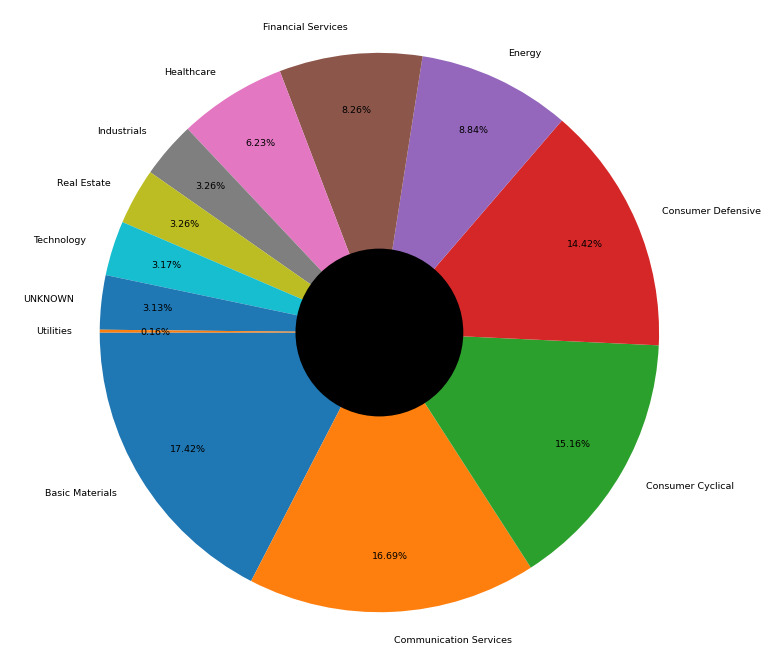

In [27]:
# Pie chart for category count distribution
sector_name = list(unique_sectors)
sizes = sector_count
# dpi --> dots per inch 
# custom_colors=['#ff7675' , '#74b9ff']
plt.figure(figsize=(2,2) , dpi=227)
plt.pie(sizes , labels=sector_name , textprops={'fontsize':3} , startangle=180 , autopct='%1.2f%%',
          radius=2 ,pctdistance=0.8)
# explode=[0.2,0.1]

# Draw Circle
centre_circle = plt.Circle((0,0) , radius=0.6 , fc='black')
plt.xticks(rotation=90)
plt.gca().add_artist(centre_circle)
plt.show()

<Axes: title={'center': 'Grade Vs Model Win '}, xlabel='Grade', ylabel='Model Win'>

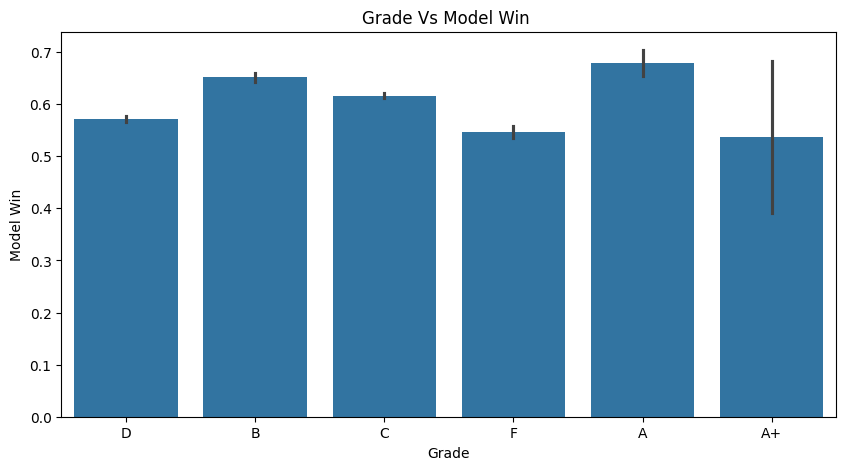

In [28]:
plt.figure(figsize=(10,5))
plt.title("Grade Vs Model Win ")
plt.xlabel("Grade")
plt.ylabel("Model Win")
sns.barplot(x="grade" , y="model_win" , data=merged_data)


Text(0, 0.5, 'Trade Win')

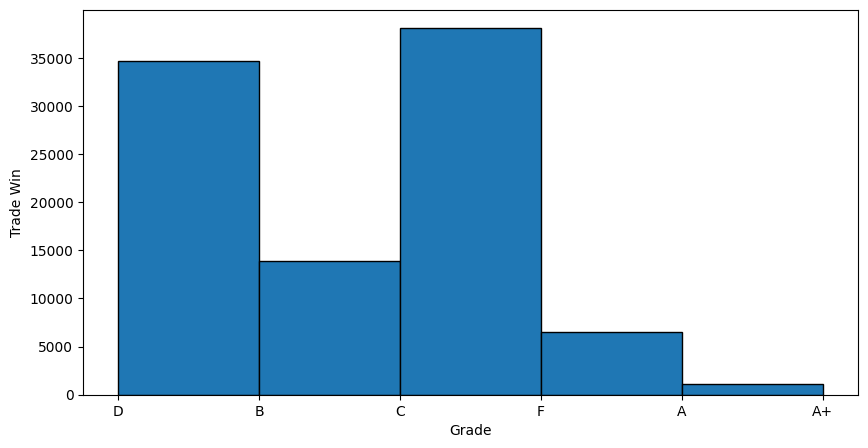

In [29]:
plt.figure(figsize=(10,5))
freq = merged_data['model_win'].value_counts
plt.hist(merged_data['grade']  , bins=5,ec ="black")
plt.xlabel("Grade")
plt.ylabel("Trade Win")


In [30]:
df = merged_data

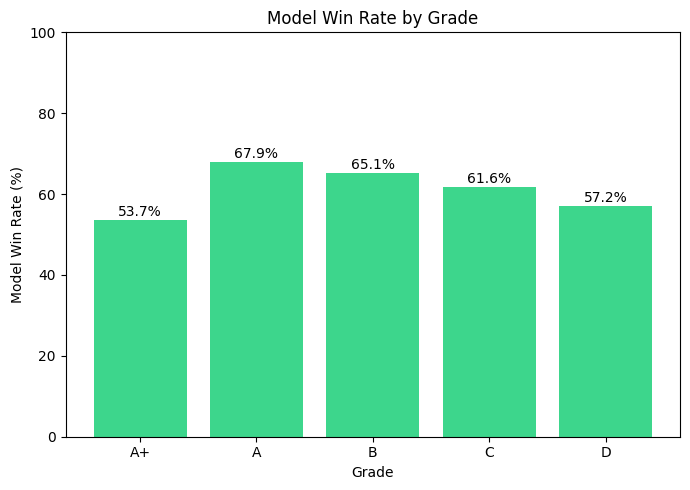

In [31]:

grade_order = ["A+", "A", "B", "C", "D"]
win_rate = (
    df.groupby("grade")["model_win"]
    .mean()
    .reindex(grade_order)
    * 100
)

plt.figure(figsize=(7, 5))
bars = plt.bar(win_rate.index, win_rate.values, color="#3dd68c")
plt.ylabel("Model Win Rate (%)")
plt.xlabel("Grade")
plt.title("Model Win Rate by Grade")
plt.ylim(0, 100)

for bar, val in zip(bars, win_rate.values):
    plt.text(bar.get_x() + bar.get_width()/2, val + 1, f"{val:.1f}%", ha="center")

plt.tight_layout()
plt.savefig("win_rate_by_grade.png", dpi=150)
plt.show()



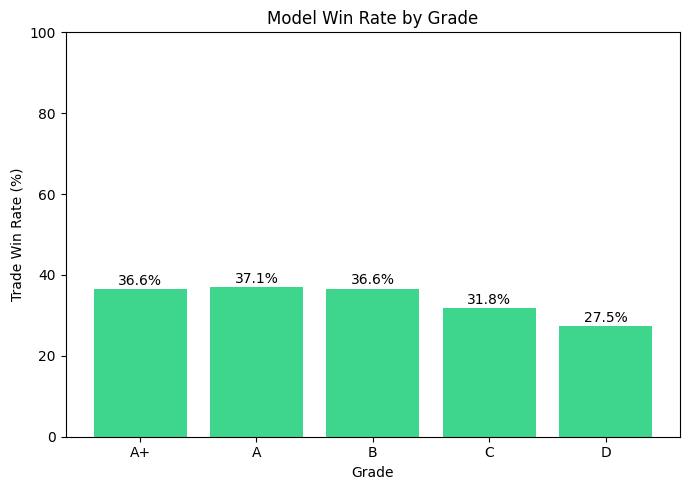

In [32]:
grade_order = ["A+", "A", "B", "C", "D"]
win_rate = (
    df.groupby("grade")["trade_win"]
    .mean()
    .reindex(grade_order)
    * 100
)

plt.figure(figsize=(7, 5))
bars = plt.bar(win_rate.index, win_rate.values, color="#3dd68c")
plt.ylabel("Trade Win Rate (%)")
plt.xlabel("Grade")
plt.title("Model Win Rate by Grade")
plt.ylim(0, 100)

for bar, val in zip(bars, win_rate.values):
    plt.text(bar.get_x() + bar.get_width()/2, val + 1, f"{val:.1f}%", ha="center")

plt.tight_layout()
plt.savefig("win_rate_by_grade.png", dpi=150)
plt.show()

In [37]:
merged_data.to_csv("../data/final_data.csv")

In [38]:
data = pd.read_csv("../data/final_data.csv")
data.head()

,Unnamed: 0,date,symbol,sector,entry,sl,t1,t2,exit_price,outcome,...,rev_direction,rev_confidence,cont_direction,cont_confidence,candle_direction,candle_confidence,sma50_above_sma200,perfect_bullish_alignment,price_above_ema9,price_above_sma50
0,0,2022-07-08,TIMETECHNO,Consumer Cyclical,53.80,49.498393,66.72,79.63,49.50,SL_HIT,...,NONE,0,BULLISH,85,BEARISH,80,1,1,1,1
1,1,2022-07-15,TIMETECHNO,Consumer Cyclical,53.07,48.826772,65.81,78.55,48.83,SL_HIT,...,NONE,0,BEARISH,100,NEUTRAL,55,1,1,0,1
2,2,2022-07-22,TIMETECHNO,Consumer Cyclical,49.74,48.992729,51.98,54.22,48.99,SL_HIT,...,BEARISH,65,BEARISH,100,BEARISH,80,1,0,0,0
3,3,2022-07-29,TIMETECHNO,Consumer Cyclical,52.10,47.931283,64.60,77.11,57.14,PARTIAL_RALLY,...,BEARISH,65,BEARISH,100,NEUTRAL,55,1,0,1,1
4,4,2022-08-05,TIMETECHNO,Consumer Cyclical,51.69,47.698402,63.65,75.61,53.77,PARTIAL_RALLY,...,BEARISH,65,BULLISH,100,NEUTRAL,55,1,0,1,1


### Ordinal encoding 


In [39]:
data.rev_direction.unique()

array(['NONE', 'BEARISH', 'BULLISH'], dtype=object)

In [40]:
data.candle_direction.unique()

array(['BEARISH', 'NEUTRAL', 'BULLISH', 'NONE'], dtype=object)

In [41]:
pat_map = {
    "BULLISH" : 1,
    "BEARISH" : -1,
    "NONE" : 0,
    "NEUTRAL" : 0
    
}
data['rev_pat'] = (data['rev_direction'].map(pat_map))*(data['rev_confidence'])/100
data['cont_pat'] = (data['cont_direction'].map(pat_map))*(data['cont_confidence'])/100

data['candle_pat'] = (data['candle_direction'].map(pat_map))*(data['candle_confidence'])/100

data.rev_pat.unique()

array([ 0.  , -0.65,  0.85, -0.85, -1.  , -0.8 ,  0.7 , -0.7 , -0.6 ,
        0.5 , -0.45, -0.5 , -0.75,  0.3 ,  0.65,  0.45, -0.3 , -0.55])

In [42]:
print(data.cont_pat.unique())
print(data.candle_pat.unique())

[ 0.85 -1.    1.   -0.9  -0.85  0.9   0.95  0.    0.75 -0.75 -0.7  -0.65
  0.7  -0.8  -0.6   0.8   0.65 -0.55  0.55  0.6 ]
[-0.8   0.    0.8   0.55 -0.55]


In [43]:
new_col_drop = ["rev_direction" , "cont_direction" , "candle_direction" , "rev_confidence" , "cont_confidence" , "candle_confidence"]
data.drop(columns=new_col_drop , inplace=True)

In [44]:
data.drop(columns=['pat_direction' , 'pat_confidence'] , inplace=True)

In [45]:
data.columns

Index(['Unnamed: 0', 'date', 'symbol', 'sector', 'entry', 'sl', 't1', 't2',
       'exit_price', 'outcome', 'return_pct', 'rel_return_pct', 'held_days',
       'grade', 'mfe_pct', 'mae_pct', 'model_win', 'trade_win', 'dow_signal',
       'strength', 'RSI_signal', 'MACD', 'MACD_signal', 'MACD_hist',
       'MACD_cross', 'BB_width', 'BB_pct', 'ATR_pct', 'Vol_ratio',
       'Dist_from_200MA', 'sma50_above_sma200', 'perfect_bullish_alignment',
       'price_above_ema9', 'price_above_sma50', 'rev_pat', 'cont_pat',
       'candle_pat'],
      dtype='object')

In [46]:
data.drop(columns=['Unnamed: 0'] , inplace=True)


In [47]:
data.drop(columns=['strength'] , inplace=True)

In [48]:
df["dow_signal"].unique()

array(['NEUTRAL', 'BUY', 'AVOID', 'STRONG BUY', 'STRONG SELL / AVOID'],
      dtype=object)

In [49]:
df.strength.unique()

array(['WEAK', 'MEDIUM', 'STRONG'], dtype=object)

In [50]:
dow_signal_map = {
    "STRONG SELL / AVOID": -2,
    "AVOID": -1,
    "NEUTRAL": 0,
    "BUY": 1,
    "STRONG BUY": 2,
}

data['dow_signal_encoded'] = data["dow_signal"].map(dow_signal_map)
data = data.drop(columns=['dow_signal'])

In [51]:
data.dow_signal_encoded.unique()

array([ 0,  1, -1,  2, -2])

In [52]:
## True/false change into binary
bool_map={
    True: 1,
    False: 0
}

data['model_win'] = data['model_win'].map(bool_map)
data['trade_win'] = data['trade_win'].map(bool_map)



In [53]:
col_rounded = ['sl' ,'MACD', 'MACD_signal', 'MACD_hist', 'BB_width', 'BB_pct' ]
for col in col_rounded:
    data[col] = round(data[col], 2)
data[col_rounded].head()

,sl,MACD,MACD_signal,MACD_hist,BB_width,BB_pct
0,49.50,1.12,0.85,0.27,16.84,0.94
1,48.83,1.30,1.22,0.08,19.99,0.67
2,48.99,0.65,1.09,-0.44,13.13,0.11
3,47.93,-0.07,0.36,-0.43,15.27,0.48
4,47.70,0.01,0.11,-0.10,15.00,0.46


In [54]:
data.columns

Index(['date', 'symbol', 'sector', 'entry', 'sl', 't1', 't2', 'exit_price',
       'outcome', 'return_pct', 'rel_return_pct', 'held_days', 'grade',
       'mfe_pct', 'mae_pct', 'model_win', 'trade_win', 'RSI_signal', 'MACD',
       'MACD_signal', 'MACD_hist', 'MACD_cross', 'BB_width', 'BB_pct',
       'ATR_pct', 'Vol_ratio', 'Dist_from_200MA', 'sma50_above_sma200',
       'perfect_bullish_alignment', 'price_above_ema9', 'price_above_sma50',
       'rev_pat', 'cont_pat', 'candle_pat', 'dow_signal_encoded'],
      dtype='object')

In [55]:
required_cols = ['MACD', 'MACD_signal', 'MACD_hist', 'MACD_cross', 'BB_width', 'BB_pct']
data[required_cols].head()

,MACD,MACD_signal,MACD_hist,MACD_cross,BB_width,BB_pct
0,1.12,0.85,0.27,NONE,16.84,0.94
1,1.30,1.22,0.08,NONE,19.99,0.67
2,0.65,1.09,-0.44,NONE,13.13,0.11
3,-0.07,0.36,-0.43,NONE,15.27,0.48
4,0.01,0.11,-0.10,NONE,15.00,0.46


In [56]:
data.MACD_cross.unique()

array(['NONE', 'BULLISH_CROSS', 'BEARISH_CROSS'], dtype=object)

In [57]:
MACD_cross_map = {
    "BULLISH_CROSS": 1,
    "BEARISH_CROSS": -1,
    "NONE": 0,
}

signal_map = {
    "BEARISH": -2,
    "OVERBOUGHT": -1,  
    "NONE": 0,
    "OVERSOLD": 1,     
    "BULLISH": 2,
}
outcome_map = {
    'SL_HIT':-1, 'PARTIAL_RALLY': 1, 'T2_HIT': 3, 'T1_HIT': 2, 'TIMEOUT': 0
}

dow_signal_map = {
    "STRONG SELL / AVOID": -2,
    "AVOID": -1,
    "NEUTRAL": 0,
    "BUY": 1,
    "STRONG BUY": 2,
}

pat_map = {
    "BULLISH" : 1,
    "BEARISH" : -1,
    "NONE" : 0,
    "NEUTRAL" : 0
    
}
merged_data["sma50_above_sma200"]      = (merged_data["SMA_50"] > merged_data["SMA_200"]).astype(int)

data['MACD_cross'] = data["MACD_cross"].map(MACD_cross_map)
data['MACD_cross'].info()

KeyError: 'SMA_50'

In [58]:
data.outcome.unique()
outcome_map = {
    'SL_HIT':-1, 'PARTIAL_RALLY': 1, 'T2_HIT': 3, 'T1_HIT': 2, 'TIMEOUT': 0
}
data['outcome'] = data['outcome'].map(outcome_map)

In [59]:
data[['outcome' , 'grade']].head()

,outcome,grade
0,-1,D
1,-1,D
2,-1,D
3,1,D
4,1,D


In [60]:
signal_map = {
    "BEARISH": -2,
    "OVERBOUGHT": -1,  
    "NONE": 0,
    "OVERSOLD": 1,     
    "BULLISH": 2,
}
data['RSI_signal'] = data["RSI_signal"].map(signal_map)


In [61]:
data.to_csv("../data/final_data.csv" , index=False)

In [62]:
data.return_pct.describe()

count    94313.000000
mean         0.893812
std          9.713413
min         -8.000000
25%         -5.040000
50%         -2.150000
75%          3.870000
max         50.000000
Name: return_pct, dtype: float64

In [63]:
data.mfe_pct.describe()

count    94313.000000
mean         8.164749
std          9.558487
min          0.000000
25%          1.530000
50%          4.560000
75%         11.410000
max         75.000000
Name: mfe_pct, dtype: float64

In [64]:
data.mae_pct.describe()

count    94313.000000
mean        -4.711862
std          3.395748
min        -78.860000
25%         -6.690000
50%         -4.170000
75%         -2.230000
max          0.000000
Name: mae_pct, dtype: float64

<Axes: xlabel='grade', ylabel='return_pct'>

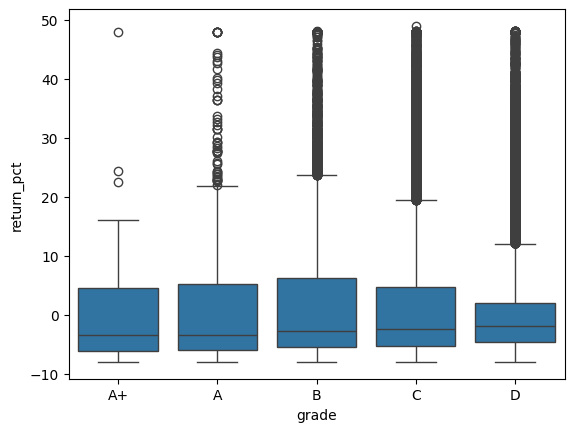

In [65]:
sns.boxplot(data=data, x="grade", y="return_pct", order=["A+","A","B","C","D"])

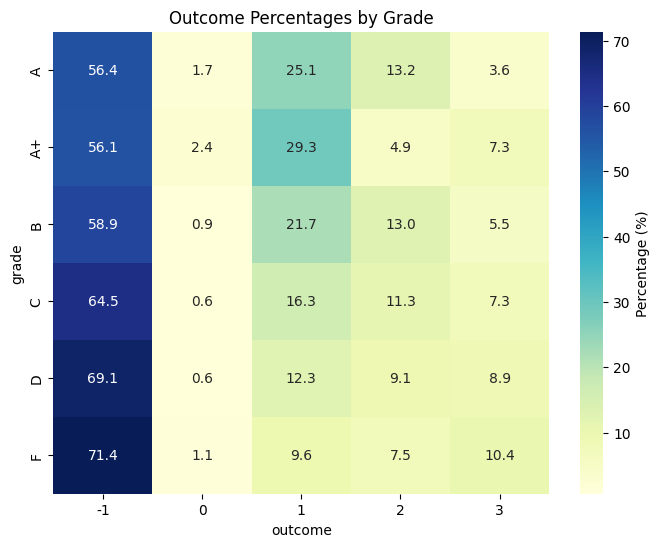

In [66]:


# 1. Generate cross-tabulation with row-wise percentages (multiplied by 100)
pct_matrix = pd.crosstab(data['grade'], data['outcome'], normalize='index') * 100

# 2. Plot the new percentage heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(pct_matrix, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={'label': 'Percentage (%)'})
plt.title("Outcome Percentages by Grade")
plt.show()


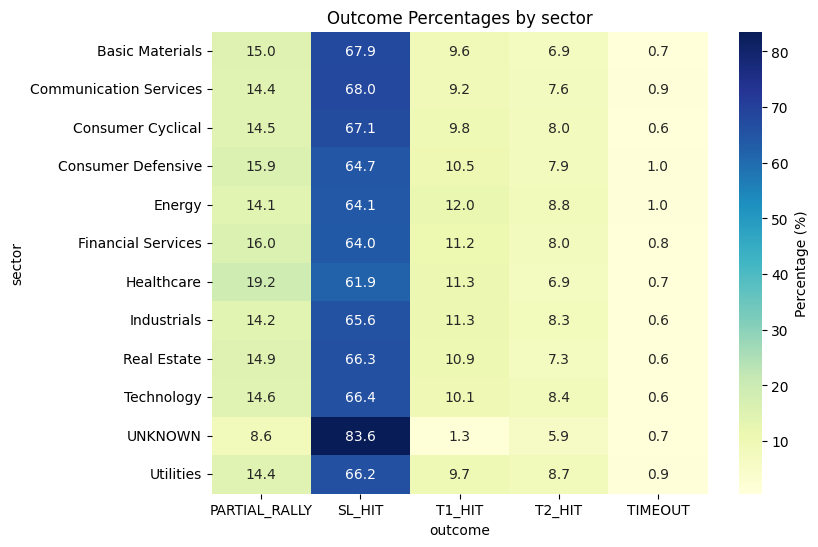

In [67]:

pct_matrix = pd.crosstab(df['sector'], df['outcome'], normalize='index') * 100

# 2. Plot the new percentage heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(pct_matrix, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={'label': 'Percentage (%)'})
plt.title("Outcome Percentages by sector")
plt.show()

## Additional Insight Visualizations (Indicators vs Win Rate, MFE/MAE, Correlations)

### 1. Boolean indicator features vs trade_win rate

In [ ]:

bool_features = ['sma50_above_sma200', 'perfect_bullish_alignment', 'price_above_ema9', 'price_above_sma50']

fig, axes = plt.subplots(1, len(bool_features), figsize=(18, 4))
for ax, feat in zip(axes, bool_features):
    rates = data.groupby(feat)['trade_win'].mean() * 100
    ax.bar(['False', 'True'], [rates.get(0, 0), rates.get(1, 0)], color=['#ff7675', '#3dd68c'])
    ax.set_title(feat)
    ax.set_ylabel('Trade Win Rate (%)')
    ax.set_ylim(0, 100)
    for i, v in enumerate([rates.get(0, 0), rates.get(1, 0)]):
        ax.text(i, v + 1, f"{v:.1f}%", ha='center')
plt.tight_layout()
plt.savefig('bool_features_vs_trade_win.png', dpi=150)
plt.show()


### 2. RSI_signal, dow_signal, MACD_cross vs trade_win

In [ ]:

signal_features = ['RSI_signal', 'dow_signal_encoded', 'MACD_cross']

fig, axes = plt.subplots(1, len(signal_features), figsize=(18, 4))
for ax, feat in zip(axes, signal_features):
    rates = data.groupby(feat)['trade_win'].mean().sort_index() * 100
    ax.bar(rates.index.astype(str), rates.values, color='#74b9ff')
    ax.set_title(f"{feat} vs Trade Win Rate")
    ax.set_ylabel('Trade Win Rate (%)')
    ax.set_ylim(0, 100)
    for i, v in enumerate(rates.values):
        ax.text(i, v + 1, f"{v:.1f}%", ha='center')
plt.tight_layout()
plt.savefig('signal_features_vs_trade_win.png', dpi=150)
plt.show()


### 3. MFE vs MAE scatter, colored by outcome (shows how far trades ran in favor vs against before resolving)

In [ ]:

outcome_labels = {-1: 'SL_HIT', 0: 'TIMEOUT', 1: 'PARTIAL_RALLY', 2: 'T1_HIT', 3: 'T2_HIT'}
plt.figure(figsize=(9, 7))
for val, label in outcome_labels.items():
    subset = data[data['outcome'] == val]
    plt.scatter(subset['mae_pct'], subset['mfe_pct'], s=6, alpha=0.35, label=label)
plt.xlabel('MAE % (max adverse excursion — worst it got against you)')
plt.ylabel('MFE % (max favorable excursion — best it got for you)')
plt.title('MFE vs MAE by Outcome')
plt.legend(markerscale=3)
plt.tight_layout()
plt.savefig('mfe_vs_mae_by_outcome.png', dpi=150)
plt.show()


### 4. Held days vs trade_win rate (does holding longer help or hurt?)

In [ ]:

plt.figure(figsize=(9, 5))
held_bins = pd.cut(data['held_days'], bins=[0, 3, 7, 14, 30, 60, data['held_days'].max()])
win_by_hold = data.groupby(held_bins, observed=True)['trade_win'].mean() * 100
win_by_hold.plot(kind='bar', color='#a29bfe')
plt.ylabel('Trade Win Rate (%)')
plt.xlabel('Held Days Bucket')
plt.title('Trade Win Rate vs Holding Period')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('win_rate_by_held_days.png', dpi=150)
plt.show()


### 5. return_pct distribution by sector (boxplot)

In [ ]:

plt.figure(figsize=(12, 6))
order = data.groupby('sector')['return_pct'].median().sort_values(ascending=False).index
sns.boxplot(data=data, x='sector', y='return_pct', order=order)
plt.xticks(rotation=45, ha='right')
plt.title('Return % Distribution by Sector')
plt.tight_layout()
plt.savefig('return_by_sector.png', dpi=150)
plt.show()


### 6. Correlation heatmap: engineered features vs trade_win / model_win / return_pct

In [ ]:

corr_cols = [
    'sma50_above_sma200', 'perfect_bullish_alignment', 'price_above_ema9', 'price_above_sma50',
    'RSI_signal', 'MACD_cross', 'MACD_hist', 'BB_pct', 'BB_width', 'ATR_pct', 'Vol_ratio',
    'Dist_from_200MA', 'rev_pat', 'cont_pat', 'candle_pat', 'dow_signal_encoded',
    'trade_win', 'model_win', 'return_pct'
]
corr_matrix = data[corr_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title('Correlation: Features vs Win/Return Targets')
plt.tight_layout()
plt.savefig('feature_correlation_heatmap.png', dpi=150)
plt.show()


### 7. A+ vs A grade deep dive — since A+ shows a lower model_win rate than A despite being the 'better' grade, compare their feature distributions directly

In [ ]:

a_plus = data[data['grade'] == 'A+']
a = data[data['grade'] == 'A']

compare_cols = ['MACD_hist', 'BB_pct', 'BB_width', 'ATR_pct', 'Vol_ratio', 'Dist_from_200MA', 'return_pct', 'mfe_pct', 'mae_pct']

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, col in zip(axes.flatten(), compare_cols):
    sns.kdeplot(a_plus[col], ax=ax, label='A+', fill=True, alpha=0.4)
    sns.kdeplot(a[col], ax=ax, label='A', fill=True, alpha=0.4)
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.savefig('a_plus_vs_a_feature_comparison.png', dpi=150)
plt.show()

print("A+ count:", len(a_plus), " | A count:", len(a))
print("A+ model_win rate:", a_plus['model_win'].mean()*100)
print("A model_win rate:", a['model_win'].mean()*100)


### 8. Outcome distribution as stacked percentage bars by grade (alternative to heatmap, easier to eyeball trends)

In [ ]:

grade_order = ["A+", "A", "B", "C", "D", "F"]
outcome_labels = {-1: 'SL_HIT', 0: 'TIMEOUT', 1: 'PARTIAL_RALLY', 2: 'T1_HIT', 3: 'T2_HIT'}

pct = pd.crosstab(data['grade'], data['outcome'], normalize='index').reindex(grade_order) * 100
pct.columns = [outcome_labels[c] for c in pct.columns]

pct.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='YlGnBu')
plt.ylabel('Percentage (%)')
plt.title('Outcome Composition by Grade (Stacked)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('outcome_stacked_by_grade.png', dpi=150)
plt.show()


### 9. Average return_pct per outcome type — and what ₹1000 per trade would turn into

In [ ]:

outcome_labels = {-1: 'SL_HIT', 0: 'TIMEOUT', 1: 'PARTIAL_RALLY', 2: 'T1_HIT', 3: 'T2_HIT'}

outcome_stats = data.groupby('outcome')['return_pct'].agg(['mean', 'median', 'std', 'count'])
outcome_stats.index = [outcome_labels[i] for i in outcome_stats.index]
outcome_stats['rupees_on_1000'] = 1000 * (1 + outcome_stats['mean']/100) - 1000
print(outcome_stats)

# Overall expected value per trade on Rs 1000
overall_mean_return = data['return_pct'].mean()
print(f"\nOverall mean return per trade: {overall_mean_return:.2f}%")
print(f"On Rs 1000 per trade, average result: Rs {1000*(1+overall_mean_return/100):.2f}  (net: Rs {1000*overall_mean_return/100:.2f})")

# Same broken down by grade
print("\n--- By grade ---")
grade_order = ["A+", "A", "B", "C", "D", "F"]
grade_returns = data.groupby('grade')['return_pct'].mean().reindex(grade_order)
for g, r in grade_returns.items():
    print(f"Grade {g}: mean return {r:.2f}%  -> Rs 1000 becomes Rs {1000*(1+r/100):.2f}")


### 10. model_win vs trade_win — actual agreement/conversion rate (crosstab, not just correlation)